# Lesson 13 pre-class prep: Reprojecting and merging

Before class, make sure you can import the data we will use in [lesson 13](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-12-merge-data/lesson-12-merge-data.html). Run the four code cells in this notebook. If they all run without errors, you are ready for class!

## About the data

We will use three datasets:

1. **Arctic communities**: a GeoJSON file with the [list of Arctic communities and their location](https://search.dataone.org/view/doi%3A10.18739%2FA28S4JQ80), created by the [Alaska Native Tribal Health Consortium](https://www.anthc.org). We will read it directly from its URL, so you don't need to download it.

2. **Countries**: [Natural Earth's medium-scale cultural boundaries data for countries (1:50m)](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/). [Natural Earth](https://www.naturalearthdata.com) is a public domain dataset with free, ready-to-use data for creating maps. To download it:
    1. Go to the [Natural Earth 1:50m cultural vectors page](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/).
    2. Under "Admin 0 – Countries", click on "Download countries".
    3. Unzip the file and move the `ne_50m_admin_0_countries` folder into a `data/` folder at the same level as this notebook.

3. **Country names**: a CSV with the country codes and names of the Arctic countries in the Arctic communities dataset. It was created for this lesson from the metadata of the Arctic communities dataset and the country names in Natural Earth's dataset. We will read it directly from its URL, so you don't need to download it.

Read the information about the datasets in the [lesson](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-12-merge-data/lesson-12-merge-data.html) before class.

## Import libraries

In [1]:
import os

import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## Import countries shapefile

In [2]:
fp = os.path.join('data', 'ne_50m_admin_0_countries', 'ne_50m_admin_0_countries.shp')
countries = gpd.read_file(fp)

# Simplify column names
countries.columns = countries.columns.str.lower()

# Select columns for analysis
countries = countries[['admin', 'type', 'geometry']]

countries.head(3)

,admin,type,geometry
0,Zimbabwe,Sovereign country,"POLYGON ((31.28789 -22.40205, 31.19727 -22.344..."
1,Zambia,Sovereign country,"POLYGON ((30.39609 -15.64307, 30.25068 -15.643..."
2,Yemen,Sovereign country,"MULTIPOLYGON (((53.08564 16.64839, 52.58145 16..."


## Import Arctic communities data

In [3]:
URL = 'https://cn.dataone.org/cn/v2/resolve/urn%3Auuid%3Aed7718ae-fb0d-43dd-9270-fbfe80bfc7a4'
communities = gpd.read_file(URL)

communities.head(3)

,name,population,country,geoname-id,geometry
0,Udomlya,32373,RU,452949,POINT (34.99250 57.87944)
1,Valmiera,26963,LV,453754,POINT (25.42751 57.54108)
2,Ventspils,42644,LV,454310,POINT (21.57288 57.38988)


## Import country names CSV

In [4]:
URL = 'https://raw.githubusercontent.com/MEDS-eds-220/MEDS-eds-220-course/refs/heads/main/book/chapters/lesson-12-merge-data/country_names.csv'
country_names = pd.read_csv(URL)

country_names.head

<bound method NDFrame.head of    country                     admin
0       RU                    Russia
1       LV                    Latvia
2       EE                   Estonia
3       LT                 Lithuania
4       SE                    Sweden
5       BY                   Belarus
6       FI                   Finland
7       NO                    Norway
8       DK                   Denmark
9       FO             Faroe Islands
10      IS                   Iceland
11      GB            United Kingdom
12      AX             Aland Islands
13      GL                 Greenland
14      US  United States of America
15      CA                    Canada>

## Quick view of geospatial data

<Axes: >

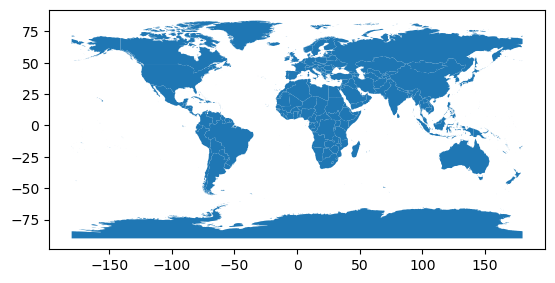

In [8]:
countries.plot()

In [ ]:
# check crs
print(countries.crs)

EPSG:4326


In [5]:
# verify that CRSs match
assert countries.crs == communities.crs

In [6]:
fig, ax = plt.subplots()
countries.plot(ax=ax)
communities.plot(ax=ax, color='red')
plt.show()

<Figure size 640x480 with 1 Axes>

## Arctic communities by country
want to calculate the number of Arctic communities by country

In [7]:
# create dataframe with number of communities per country
n_comms = communities.groupby('country').size().reset_index(name = 'n_communities')

goal: merge the `n_comms` and the `countries` data frames
to merge the two data frames, they need to have at least one column in common

In [8]:
set(countries.columns).intersection(n_comms.columns)

set()

In [9]:
common_columns = set(countries.columns).intersection(n_comms.columns)

#check if there are any common columns, 
if len(common_columns)!= 0:
    print(f"common columns: {common_columns}")
else:
    print("no common columns")

no common columns


convert previous code into a function called `check_common_columns`, that takes in two data frames as arguments

In [10]:
def check_common_columns(df1, df2):

 common_columns = set(df1.columns).intersection(df2.columns)

#check if there are any common columns, 
if len(common_columns)!= 0:
        print(f"common columns: {common_columns}")
else:
        print("no common columns")


no common columns


In [11]:
check_common_columns(countries, n_comms)

## Merge data frames
use `country_names` dataframe to add the country names into the `n_comms`. 
To merge the data frames, we can use `pandas.merge()` function

```python
output_df = pd.merge(left_df, 
                    right_df, 
                    how = type_of_join, 
                    on = column_to_join)
```
where
 - `output_df` = df resulting from merge
 - `left_join` = df we have 'on the left side'
 - `right_df` = df 'on the right side'
 - `how` = type of join
 - `on` = column to join on, must be present on both dataframes


In [ ]:
check_common_columns

In [12]:
n_comms = pd.merge(n_comms, 
                   country_names,
                   how='left', 
                   on='country')

n_comms

,country,n_communities,admin
0,AX,1,Aland Islands
1,BY,8,Belarus
2,CA,7,Canada
3,DK,72,Denmark
4,EE,14,Estonia
5,FI,98,Finland
6,FO,1,Faroe Islands
7,GB,96,United Kingdom
8,GL,1,Greenland
9,IS,5,Iceland


In [25]:
check_common_columns(n_comms, countries)

In [13]:
arctic_countries = pd.merge(countries, 
                   n_comms,
                   how='inner', 
                   on='admin')

In [14]:
arctic_countries = countries.merge(n_comms, 
                                   how = 'inner', 
                                   on = 'admin')

arctic_countries

,admin,type,geometry,country,n_communities
0,United States of America,Country,"MULTIPOLYGON (((-132.74687 56.52568, -132.7576...",US,115
1,United Kingdom,Country,"MULTIPOLYGON (((-2.66768 51.62300, -2.74214 51...",GB,96
2,Sweden,Sovereign country,"MULTIPOLYGON (((19.07646 57.83594, 18.99375 57...",SE,133
3,Russia,Sovereign country,"MULTIPOLYGON (((145.88154 43.45952, 145.89561 ...",RU,774
4,Norway,Sovereign country,"MULTIPOLYGON (((20.62217 69.03687, 20.49199 69...",NO,48
5,Lithuania,Sovereign country,"MULTIPOLYGON (((20.95781 55.27891, 20.89980 55...",LT,26
6,Latvia,Sovereign country,"POLYGON ((26.59355 55.66753, 26.54287 55.67241...",LV,25
7,Iceland,Sovereign country,"POLYGON ((-15.54312 66.22852, -15.42847 66.224...",IS,5
8,Finland,Country,"MULTIPOLYGON (((24.15547 65.80527, 24.04902 65...",FI,98
9,Estonia,Sovereign country,"MULTIPOLYGON (((27.35195 57.52812, 27.32656 57...",EE,14


Note: when merging with a geoDataFrame, the GeoDataFrame needs to be on the left to keep the geometries.

## Review the results

In [15]:
print(f"Countries in the n_comms: {len(n_comms)}")
print(f"Countries in the arctic_countries: {len(arctic_countries)}")


Countries in the n_comms: 16
Countries in the arctic_countries: 15


In [16]:
# countries in n_comms without a match in countries
n_comms[~n_comms['admin'].isin(countries['admin'])]

,country,n_communities,admin
0,AX,1,Aland Islands


In [17]:
countries[countries['admin'].str.contains('Aland')]

,admin,type,geometry
168,Aland,Country,"MULTIPOLYGON (((19.98955 60.35117, 20.02021 60..."


In [18]:
# match the name used in the countries data
n_comms['admin']=n_comms['admin'].replace('Aland Islands', 'Aland')

#merge again
arctic_countries = countries.merge(n_comms, how='inner', on = 'admin')

print(f"countries in arctic_communities: {len(arctic_countries)}")

countries in arctic_communities: 16


# Choropleth map


<Axes: >

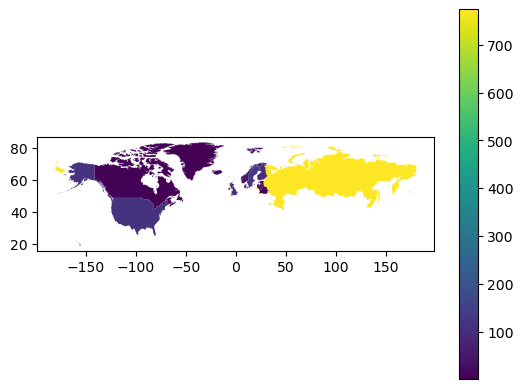

In [19]:
arctic_countries.plot(column='n_communities', 
                      legend=True)

## Reprojecting 

In [21]:
# Reproject to CRS optimised for an Arctic Region
arctic_countries = arctic_countries.to_crs('epsg:3413')
arctic_countries.crs

<Projected CRS: EPSG:3413>
Name: WGS 84 / NSIDC Sea Ice Polar Stereographic North
Axis Info [cartesian]:
- X[south]: Easting (metre)
- Y[south]: Northing (metre)
Area of Use:
- name: Northern hemisphere - north of 60°N onshore and offshore, including Arctic.
- bounds: (-180.0, 60.0, 180.0, 90.0)
Coordinate Operation:
- name: US NSIDC Sea Ice polar stereographic north
- method: Polar Stereographic (variant B)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

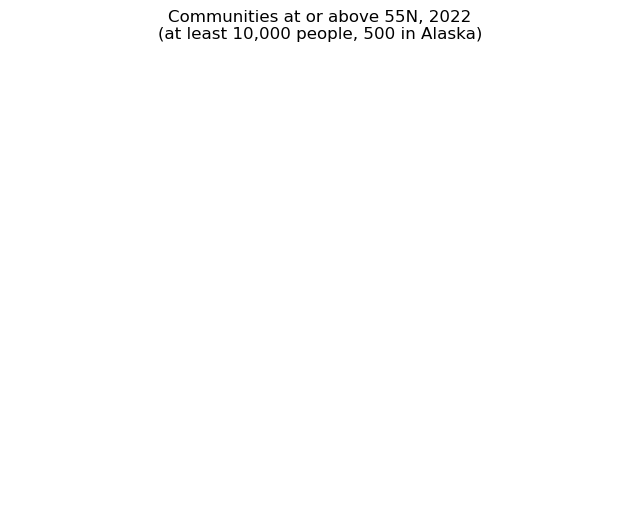

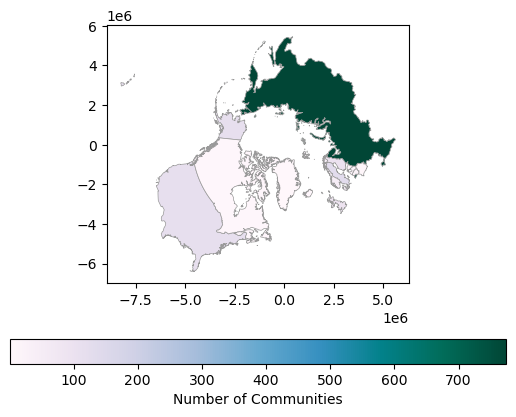

In [27]:
fig, ax = plt.subplots(figsize=(8,6))
ax.axis('off')
arctic_countries.plot(column='n_communities', 
                      legend=True,
                      edgecolor="0.6",
                      linewidth= 0.5,
                      cmap='PuBuGn', 
                      legend_kwds={
                          "label":"Number of Communities", 
                          "orientation": "horizontal"
                      })

ax.set_title("Communities at or above 55N, 2022\n(at least 10,000 people, 500 in Alaska)")
plt.show()